# 01 · From Bayes' Theorem to a Classifier

> **Build-up:** Bayes → classifier → *Naive Bayes is counting* → the spam filter →
> right decision, wrong probability → when it wins and loses → practical guide.

Bayes' theorem tells us how probable a class is *given* the evidence. A classifier just
picks the most probable class. This notebook walks that one step — and introduces the
single simplifying assumption (feature independence) that is **false on real data** yet
makes everything tractable. That contradiction is the paradox the rest of the project
resolves.

All figures are saved to `outputs/figures/*.png` and all numbers to `outputs/data/*.json`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src import artifacts
from src.models import MultinomialNB

np.set_printoptions(precision=4, suppress=True)

## 1. The theorem, then the rule

For a class $c$ and an observed feature vector $x = (x_1, \dots, x_d)$:

$$ P(c \mid x) = \frac{P(c)\,P(x \mid c)}{P(x)} $$

The denominator $P(x)$ is the same for every class, so to **decide** we only compare the
numerators and pick the biggest:

$$ \hat{c} = \arg\max_c \; P(c)\,P(x \mid c) $$

That is already a classifier. The only hard part is $P(x \mid c)$ — the joint probability
of *all* the features together.

## 2. The "naive" assumption (and why it is false)

Modelling the full joint $P(x_1, \dots, x_d \mid c)$ is intractable. Naive Bayes makes one
move: **assume every feature is independent of every other, given the class.** Then the
joint collapses into a simple product:

$$ P(x \mid c) = \prod_{j=1}^{d} P(x_j \mid c) \qquad\Rightarrow\qquad
   \hat{c} = \arg\max_c \; P(c)\prod_{j=1}^{d} P(x_j \mid c) $$

This is **false on essentially all real data** — in text, seeing *"san"* makes *"francisco"*
far more likely; features correlate everywhere. We adopt it anyway, flag it as a lie, and
spend the project watching it win regardless.

## 3. A worked example, by hand

Two classes — **spam** and **ham** — and a three-word vocabulary. We have the total word
counts per class from training, then classify the message **"free money"** by hand, with
Laplace (add-one) smoothing so no probability is ever zero.

In [2]:
vocab = ["free", "money", "friend"]
# Rows = per-class total word counts gathered in training (one "pseudo-document" per class).
counts = np.array(
    [
        [6.0, 5.0, 1.0],   # spam: free x6, money x5, friend x1   (12 words)
        [1.0, 1.0, 8.0],   # ham:  free x1, money x1, friend x8   (10 words)
    ]
)
y = np.array([1, 0])          # 1 = spam, 0 = ham  (one document each -> equal priors)
alpha = 1.0                   # Laplace smoothing
V = len(vocab)

# P(word | class) by counting, with add-one smoothing.
likelihood = (counts + alpha) / (counts.sum(axis=1, keepdims=True) + alpha * V)
prior = np.array([0.5, 0.5])  # spam, ham

doc = np.array([1, 1, 0])     # "free money" -> free x1, money x1, friend x0
# Unnormalised score P(class) * prod P(word|class) over the words present.
score_spam = prior[0] * np.prod(likelihood[0] ** doc)
score_ham = prior[1] * np.prod(likelihood[1] ** doc)
post_spam = score_spam / (score_spam + score_ham)
post_ham = 1.0 - post_spam

print("P(word|spam):", dict(zip(vocab, likelihood[0])))
print("P(word|ham) :", dict(zip(vocab, likelihood[1])))
print(f"Posterior  P(spam | 'free money') = {post_spam:.4f}")
print(f"Posterior  P(ham  | 'free money') = {post_ham:.4f}")

P(word|spam): {'free': np.float64(0.4666666666666667), 'money': np.float64(0.4), 'friend': np.float64(0.13333333333333333)}
P(word|ham) : {'free': np.float64(0.15384615384615385), 'money': np.float64(0.15384615384615385), 'friend': np.float64(0.6923076923076923)}
Posterior  P(spam | 'free money') = 0.8875
Posterior  P(ham  | 'free money') = 0.1125


## 4. The from-scratch model agrees

Our `MultinomialNB` (built in notebook 02) is doing exactly this arithmetic. Feeding it the
same per-class counts reproduces the hand calculation to machine precision.

In [3]:
model = MultinomialNB(alpha=alpha).fit(counts, y)
proba = model.predict_proba(doc.reshape(1, -1))[0]
spam_index = int(np.where(model.classes_ == 1)[0][0])

print(f"Model P(spam | 'free money') = {proba[spam_index]:.4f}")
assert np.isclose(proba[spam_index], post_spam), "model and hand calc disagree!"
print("hand calculation and from-scratch model agree")

artifacts.save_json(
    {
        "vocabulary": vocab,
        "class_counts": counts.tolist(),
        "prior": {"spam": prior[0], "ham": prior[1]},
        "likelihood": {
            "spam": dict(zip(vocab, likelihood[0].tolist())),
            "ham": dict(zip(vocab, likelihood[1].tolist())),
        },
        "message": "free money",
        "posterior": {"spam": float(post_spam), "ham": float(post_ham)},
        "decision": "spam" if post_spam > post_ham else "ham",
    },
    "01_hand_worked_example",
)

Model P(spam | 'free money') = 0.8875
hand calculation and from-scratch model agree


PosixPath('/workspaces/naive_bayes_101/outputs/data/01_hand_worked_example.json')

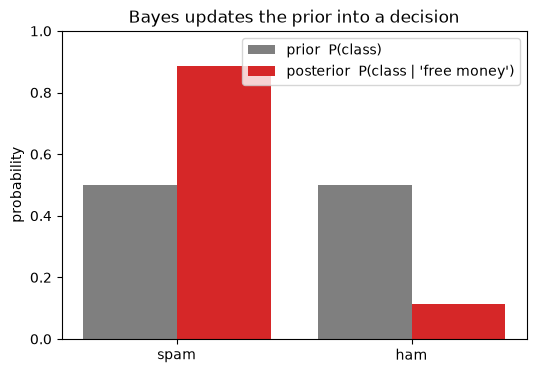

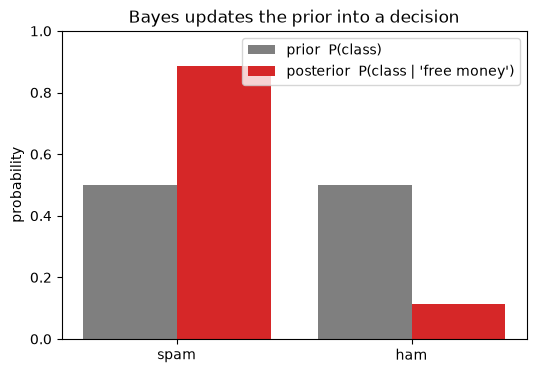

In [4]:
# Prior vs posterior: the evidence in "free money" pulls a 50/50 prior toward spam.
labels = ["spam", "ham"]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - 0.2, prior, width=0.4, label="prior  P(class)", color="tab:gray")
ax.bar(x + 0.2, [post_spam, post_ham], width=0.4, label="posterior  P(class | 'free money')",
       color="tab:red")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_ylabel("probability")
ax.set_title("Bayes updates the prior into a decision")
ax.legend()
artifacts.save_fig(fig, "01_prior_vs_posterior")
fig

## Takeaway

The classifier fell straight out of Bayes' theorem: **pick the class with the highest
posterior.** The only addition was the independence assumption, which turned an intractable
joint into a product of per-feature probabilities — and which is a lie on real data.

Next (**notebook 02**): training this model is nothing but *counting*, and one unseen word
can break it unless we smooth.